In [1]:
import torch
from torch.distributions import MultivariateNormal
import numpy as np
import matplotlib.pyplot as plt
import scienceplots
import torch.nn as nn
from torch.distributions import Uniform
import gc
import math
import time


plt.style.use(['science', 'notebook', 'grid'])
torch.set_default_device("cuda")
torch.manual_seed(0)

covariance computation time: 0.020660800000769086
loop time: 67.39338000043062
Step: 0, Loss: 17.96021270751953
Error (rel-rmse): 126.53643035888672

loop time: 24.40931000019191
Step: 100, Loss: -5.227691650390625
Error (rel-rmse): 91.06283569335938

loop time: 30.62665999896126
Step: 200, Loss: -9.416287422180176
Error (rel-rmse): 82.3055648803711

loop time: 35.34436999907484
Step: 300, Loss: -12.994540214538574
Error (rel-rmse): 75.12916564941406

loop time: 33.53470000001835
Step: 400, Loss: -16.140907287597656
Error (rel-rmse): 68.88175964355469

loop time: 35.12057000043569
Step: 500, Loss: -17.627845764160156
Error (rel-rmse): 63.390220642089844

loop time: 33.38388999982271
Step: 600, Loss: -19.482288360595703
Error (rel-rmse): 58.52956771850586

loop time: 33.532060000288766
Step: 700, Loss: -20.42479705810547
Error (rel-rmse): 54.0577392578125

loop time: 34.646250000514556
Step: 800, Loss: -22.884613037109375
Error (rel-rmse): 50.14676284790039

loop time: 41.09794999967562

C:\Users\erics\AppData\Local\Temp\ipykernel_39020\2218961002.py:181: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc='upper right', fontsize=10)
C:\Users\erics\AppData\Local\Temp\ipykernel_39020\2218961002.py:188: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc='upper right', fontsize=10)


Text(0, 0.5, 'error')

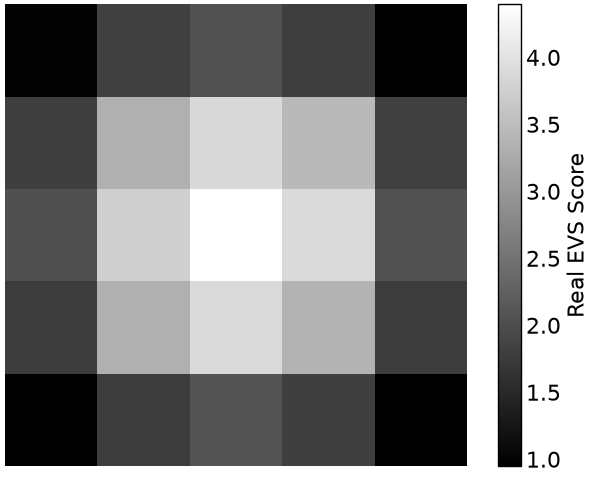

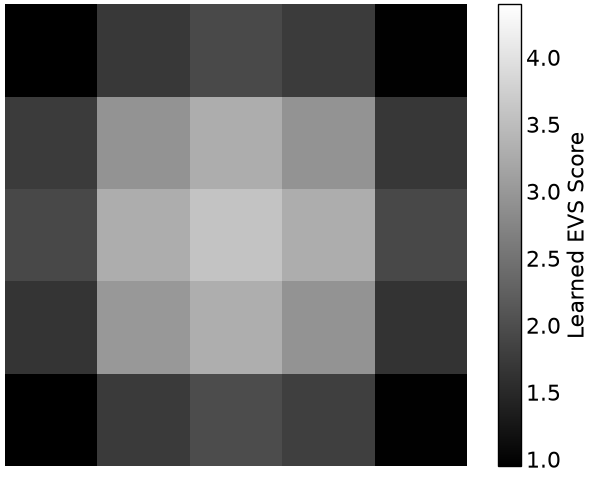

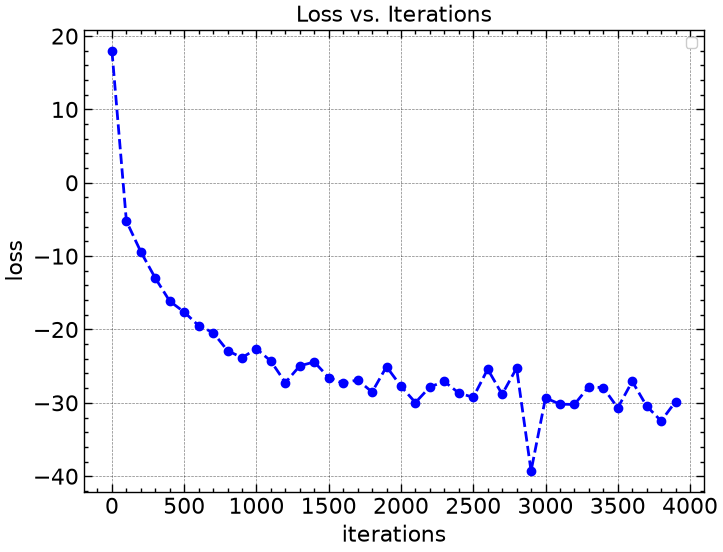

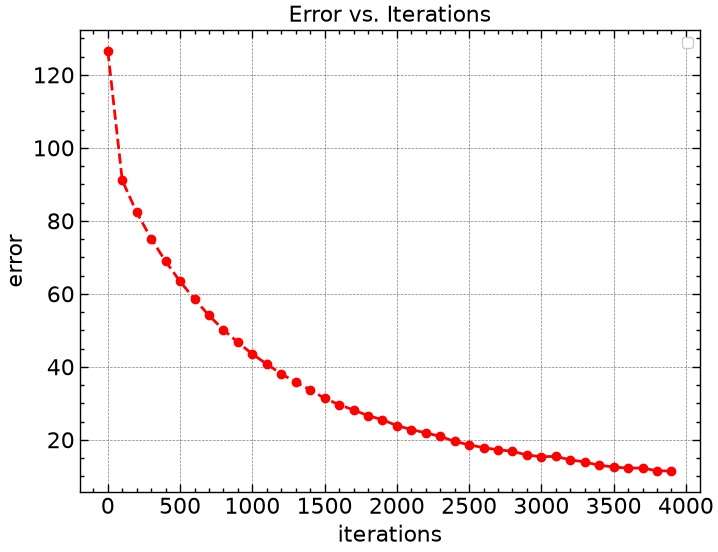

In [11]:
d = 5
    # Image height and width
N = 10000
    # Number of samples
lr = .003
    # Learning rate
steps = 4000
    # Number optimization iterations
M = 1
    # How many random vectors to estimate Hessian trace
B = 256
    # Mini batch size


mu = torch.ones(d ** 2,)

var = 2
L = 1
eps = .000

st1 = time.perf_counter()
def cov_comp(var, L):
    temp = torch.zeros(d ** 2, d ** 2)
    for n in range(temp.shape[0]):
            i_1 = n // d
            j_1 = n % d
            for m in range(temp.shape[1]):
                i_2 = m // d
                j_2 = m % d

                dist_squared = (i_1 - i_2) ** 2 + (j_1 - j_2) ** 2
                temp[m][n] = (var ** 2) * math.exp(- dist_squared / (2 * (L ** 2)))
    return temp

cov = cov_comp(var, L) + torch.eye(d ** 2,) * eps

et1 = time.perf_counter()

print(f"covariance computation time: {et1 - st1}")


dist = MultivariateNormal(mu, cov)
samples = dist.sample((N,)).detach().requires_grad_(True)

score_nn = nn.Linear(d ** 2, d ** 2, bias=True)
optimizer = torch.optim.Adam(score_nn.parameters(), lr=lr)


tr_dist = MultivariateNormal(torch.zeros(d **2, ), torch.eye(d ** 2, ))
def trace(score, data, i):
    tr_sample = tr_dist.sample((i,))
    vec_hess = torch.autograd.grad(outputs = score(data), inputs = data, grad_outputs=tr_sample, create_graph=True, retain_graph=True, is_grads_batched=True,)[0]
    return (tr_sample * vec_hess).sum(dim=1).mean()

    


     
def loss(score, data):
    vals = score(data)
    norm = 0.5 * vals.square().sum(dim=1)
    ttrace = torch.stack([trace(score, x,M) for x in data])
    return (ttrace + norm).mean()







storex = torch.zeros(steps // 100, )
storey = torch.zeros(steps // 100, )


estorex = torch.zeros(steps // 100, )
estorey = torch.zeros(steps // 100, )

test_set = dist.sample((N,)).requires_grad_()

def rmse(act,learned,x):
    return (((learned(x) - act(x)) ** 2).mean()) ** 0.5
    # Sqrt of mean squared error
        # .mean(): mean along all entries in tensor


def rel_rmse(act,learned,x):
    denom = ((act(x) ** 2).mean()) ** 0.5
        # Mean of actual squared
    return (rmse(act,learned,x) / denom) * 100
        # Used to make sqrt of MSE a unitless percen    tage for easy interpretability

def actual(x):
    return (torch.linalg.inv(cov) @ (mu - x).T).T

def EVS(x):
    return (x ** 2).mean(dim=0)

for step in range(steps):
    stl = time.perf_counter()
        # Main training loop
    
    # st2 = time.perf_counter()
    indices = torch.randperm(N, device=samples.device)[:B]
    batch = samples[indices].detach().requires_grad_(True)
    loss_store = loss(score_nn, batch)
    # et2 = time.perf_counter()
    # print(f"Loss calc + trace: {et2-st2}")

    # st3 = time.perf_counter()
    optimizer.zero_grad()
    # et3 = time.perf_counter()
    # print(f"zero out grads calc: {et3-st3}")

            # Clear out gradients to not add from last loop
    # st3 = time.perf_counter()
    loss_store.backward()
    # et3 = time.perf_counter()
    # print(f"backprop calc: {et3-st3}")

        # Calculates gradients with respect to parameters in Adam
    # st4 = time.perf_counter()
    optimizer.step()
    # et4 = time.perf_counter()
    # print(f"grad decent calc: {et4-st4}")
    etl = time.perf_counter()
    if step % 100 == 0:
        print(f"loop time: {100 * (etl - stl)}")



        # Calculated the Adam gradient descent
    if step % 100 == 0:
        print(f"Step: {step}, Loss: {loss_store}")
        storex[step // 100] = step
        storey[step // 100] = loss_store
        estorex[step // 100] = step
        estorey[step // 100] = rel_rmse(actual,score_nn,test_set)
        print(f"Error (rel-rmse): {rel_rmse(actual,score_nn,test_set)}")
        print("")
    # if step == 1800:
    #     for param_group in optimizer.param_groups:
    #        param_group["lr"] = 0.00003
    # if step == 5000:
    #     for param_group in optimizer.param_groups:
    #         param_group["lr"] = 0.00008





print(f"Error evaluated on training set (rel-rmse): {rel_rmse(actual,score_nn,samples)}")



storex = storex.detach().cpu().numpy()
storey = storey.detach().cpu().numpy()



estorex = estorex.detach().cpu().numpy()
estorey = estorey.detach().cpu().numpy()



plt.figure()
plt.imshow(EVS(actual(test_set)).reshape(d, d).detach().cpu().numpy(), cmap="gray", vmin=EVS(actual(test_set)).min().item(), vmax=EVS(actual(test_set)).max().item())
plt.colorbar(label="Real EVS Score")
plt.axis("off")


plt.figure()
plt.imshow(EVS(score_nn(test_set)).reshape(d, d).detach().cpu().numpy(), cmap="gray", vmin=EVS(actual(test_set)).min().item(), vmax=EVS(actual(test_set)).max().item())
plt.colorbar(label="Learned EVS Score")
plt.axis("off")



plt.figure()
plt.title("Loss vs. Iterations")
plt.plot(storex, storey, 'o--', color='blue')
plt.legend(loc='upper right', fontsize=10)
plt.xlabel('iterations')
plt.ylabel('loss')

plt.figure()
plt.title("Error vs. Iterations")
plt.plot(estorex, estorey, 'o--', color='red')
plt.legend(loc='upper right', fontsize=10)
plt.xlabel('iterations')
plt.ylabel('error')


(np.float64(-0.5), np.float64(4.5), np.float64(4.5), np.float64(-0.5))

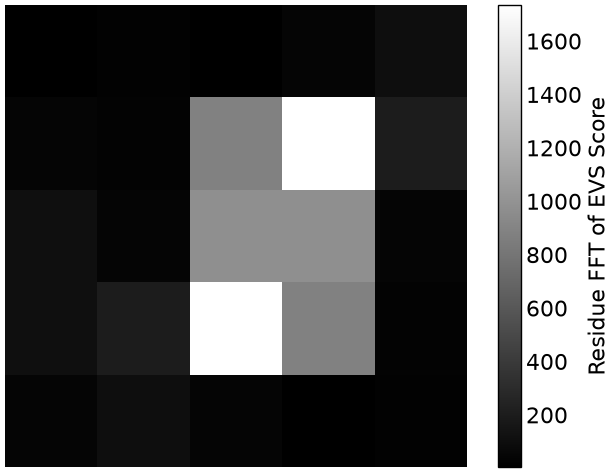

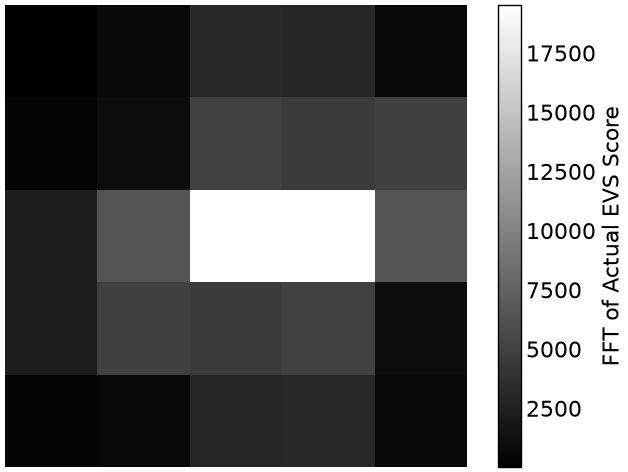

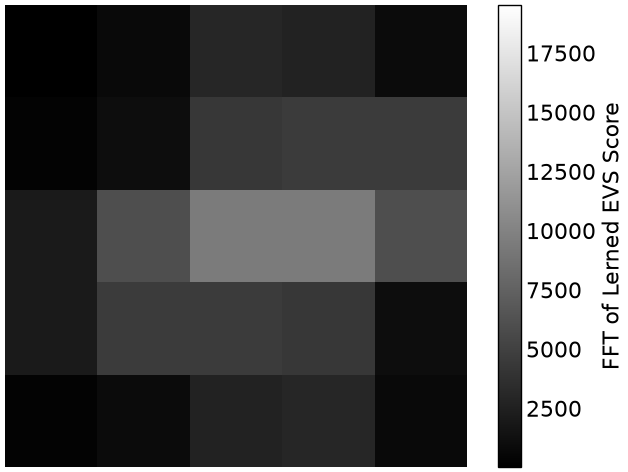

In [12]:






fim_raw_res = (actual(test_set) - score_nn(test_set))
fim_res = EVS(torch.fft.fft2(fim_raw_res)).reshape(d, d)

fim_raw_act = actual(test_set)
fim_act = EVS(torch.fft.fft2(fim_raw_act)).reshape(d, d)

fim_raw_score = score_nn(test_set)
fim_score = EVS(torch.fft.fft2(fim_raw_score)).reshape(d, d)

plt.figure()
plt.imshow(fim_res.abs().detach().cpu().numpy(), cmap="gray", vmin=fim_res.abs().min().item(), vmax=fim_res.abs().max().item())
plt.colorbar(label="Residue FFT of EVS Score")
plt.axis("off")


plt.figure()
plt.imshow(fim_act.abs().detach().cpu().numpy(), cmap="gray", vmin=fim_act.abs().min().item(), vmax=fim_act.abs().max().item())
plt.colorbar(label="FFT of Actual EVS Score")
plt.axis("off")


plt.figure()
plt.imshow(fim_score.abs().detach().cpu().numpy(), cmap="gray", vmin=fim_act.abs().min().item(), vmax=fim_act.abs().max().item())
plt.colorbar(label="FFT of Lerned EVS Score")
plt.axis("off")

temp = torch.zeros(i, )
    for j in range(i):
        vec_hess = torch.autograd.grad(outputs = score(data) @ tr_sample[j], inputs = data, create_graph=True, retain_graph=True,)[0]
        temp[j] = tr_sample[j] @ vec_hess
    return temp.mean()


    temp = torch.zeros(B, )
    for i in range(B, ):
        temp[i] =  0.5 * (torch.linalg.vector_norm(score(data[i]), ord=2)) ** 2 + trace(score, data[i], M)
    return temp.mean()